Progetto 3

Implementare e confrontare due diversi algoritmi di classificazione, K-Nearest

Neighbors (KNN) e Support Vector Machine (SVM), dopo aver ridotto la di-

mensionalit`a del dataset Wine utilizzando la PCA.

1 Data Exploration & Preprocessing

• Caricamento e Analisi del dataset e fornire un’analisi descrittiva iniziale

(i.e. df.describe(), df.dtypes)

• Standardization delle feature (X) per garantire che tutti gli attributi

abbiano media zero e deviazione standard unitaria

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.decomposition import PCA

In [5]:
data = load_wine()
X, y = data.data, data.target
display(pd.DataFrame(X, columns=data.feature_names).describe().dtypes)
display(pd.DataFrame(y, columns=['target']).describe().dtypes)

alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
dtype: object

target    float64
dtype: object

In [26]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

2 Data Dimensionality Reduction

• Applicare la PCA (Principal Component Analysis) sui dati standardizzati

• Ridurre la dimensionalit`a a 2 componenti principali (n components=2)

per facilitare la visualizzazione

In [27]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

3 Addestramento & Valutazione

• Inizializzare due modelli:

1. K-Nearest Neighbors (KNN) con n neighbors=5

2. Support Vector Machine (SVM) con kernel=’linear’

• Addestrare entrambi i modelli utilizzando il dataset ridotto a 2 componenti

• Calcolare e stampare l’Accuracy Score di entrambi i modelli sull’intero set

di dati ridotto

In [28]:
k_range = range(1, 21)

error_rate = []

k_range_odd = [k for k in k_range if k % 2 != 0]

for k in k_range_odd:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_scaled, y)
    y_pred = knn.predict(X_scaled)
    error_rate.append(1 - accuracy_score(y, y_pred))

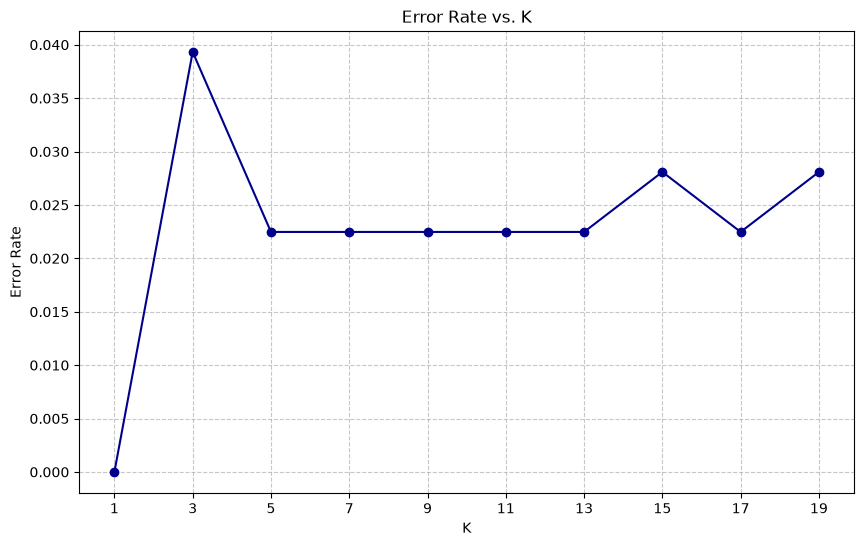

In [29]:
plt.figure(figsize=(10, 6))
plt.plot(k_range_odd, error_rate, marker='o', linestyle='-', color='darkblue')
plt.xlabel('K')
plt.ylabel('Error Rate')
plt.xticks(k_range_odd)
plt.title('Error Rate vs. K')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [31]:
best_k = 5
knn_final = KNeighborsClassifier(n_neighbors=best_k)
feature_0 = 0
feature_1 = 1
X_2d = X_scaled[:, [feature_0, feature_1]]
knn_final.fit(X_2d, y)
y_pred_final = knn_final.predict(X_2d)
accuracy_final = accuracy_score(y, y_pred_final)
print(f"Accuracy for final K ({best_k}) with features {feature_0} and {feature_1}: {accuracy_final}")

Accuracy for final K (5) with features 0 and 1: 0.8595505617977528


In [32]:
best_k = 5
svm_final = SVC(kernel='linear')
feature_0 = 0
feature_1 = 1
X_2d = X_scaled[:, [feature_0, feature_1]]
svm_final.fit(X_2d, y)
y_pred_final = svm_final.predict(X_2d)
accuracy_final = accuracy_score(y, y_pred_final)
print(f"Accuracy for final K ({best_k}) with features {feature_0} and {feature_1}: {accuracy_final}")

Accuracy for final K (5) with features 0 and 1: 0.7865168539325843


4 Analisi & Visualizzazione

• Generare un grafico con due subplot per confrontare i risultati visivi

• Plottare i data points colorati in base alla loro classe di appartenenza

(target)

• Visualizzare i decision boundary dei modelli (KNN e SVM)

Text(0.5, 1.0, 'SVC Decision Boundary')

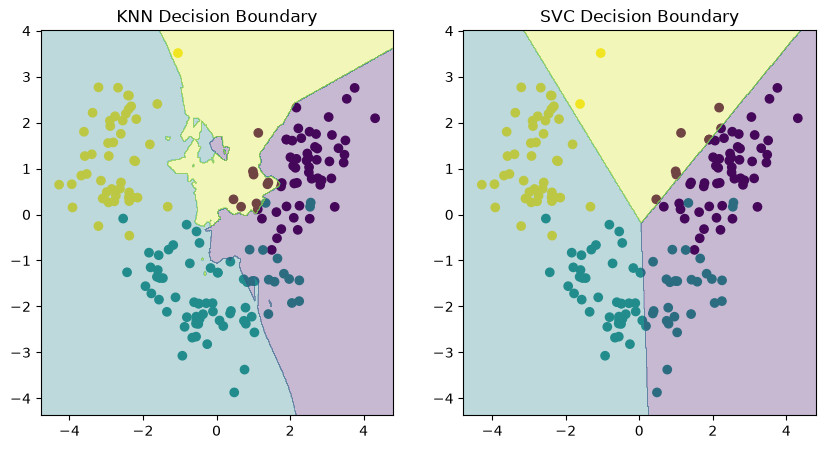

In [33]:
x_min, x_max = X_pca[:,0].min() - 0.5, X_pca[:,0].max() + 0.5
y_min, y_max = X_pca[:,1].min() - 0.5, X_pca[:,1].max() + 0.5

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))            
    
Z = knn_final.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.scatter(X_pca[:,0], X_pca[:,1], c=y)
plt.contourf(xx, yy, Z, alpha=0.3)
plt.title("KNN Decision Boundary")
plt.subplot(1,2,2)
plt.scatter(X_pca[:,0], X_pca[:,1], c=y)
Z_svm = svm_final.predict(np.c_[xx.ravel(), yy.ravel()])
Z_svm = Z_svm.reshape(xx.shape)
plt.contourf(xx, yy, Z_svm, alpha=0.3)
plt.title("SVC Decision Boundary")